# **Start Section:**

In [1]:
# FIX K1: same notebook runs on Google Colab (Drive) or Kaggle (internet on).
# On Kaggle the working dir is /kaggle/working, so the original "./drive/MyDrive/..." paths
# below are reused unchanged; the dataset is copied there as train.csv / test.csv.
import os, glob, shutil
IN_KAGGLE = os.path.exists("/kaggle/working")
if IN_KAGGLE:
    _data_dir = "./drive/MyDrive/Regression/concrete_uncertainty_analysis/data"
    os.makedirs(_data_dir, exist_ok=True)
    shutil.copy(glob.glob("/kaggle/input/**/d05_a.csv", recursive=True)[0], f"{_data_dir}/train.csv")  # concrete train
    shutil.copy(glob.glob("/kaggle/input/**/d05_b.csv", recursive=True)[0], f"{_data_dir}/test.csv")   # concrete test
    print("Kaggle: concrete data copied to", _data_dir)
else:
    from google.colab import drive
    drive.mount('/content/drive')


Kaggle: concrete data copied to ./drive/MyDrive/Regression/concrete_uncertainty_analysis/data


In [2]:
# FIX K1: original Colab install block kept as-is (runs only on Colab).
# On Kaggle: install only the packages the Kaggle image lacks, pinned to the Colab versions,
# and do NOT restart the kernel.
if IN_KAGGLE:
    !pip install -q optuna==4.6.0 optunahub==0.4.0 cmaes==0.12.0 xgboost==3.1.2 catboost==1.2.8 gpboost==1.6.1 ngboost==0.5.8 pgbm==2.2.0 pytorch-tabnet2==4.5.3 interpret==0.7.4 lime==0.2.0.1 bayesian-optimization==3.2.0 properscoring==0.1 XlsxWriter==3.2.9 mapie==0.6.0 puncc==0.8.0
else:
    import os
    os.environ["PIP_CONSTRAINT"] = "/tmp/numpy_constraint.txt"
    !echo "numpy==1.26.4" > /tmp/numpy_constraint.txt

    !pip uninstall -y torch torchaudio torchvision \
        torchao torchcodec torchdata torchtune torchsummary -q 2>/dev/null

    !pip uninstall -y tensorflow tensorflow-text tensorflow-hub tf-keras \
        tensorflow_decision_forests tensorflow-probability \
        tensorflow-Datasets tensorflow-metadata -q 2>/dev/null

    !pip uninstall -y numpy scikit-learn shap xgboost lightgbm dask \
        seaborn plotly openpyxl Cython catboost interpret lime -q 2>/dev/null

    !pip install numpy==1.26.4 -q
    !pip install scikit-learn==1.6.1 -q
    !pip install torch==2.9.0 -q

    !pip install lightgbm==4.6.0 -q
    !pip install xgboost==3.1.2 -q
    !pip install catboost==1.2.8 -q
    !pip install gpboost==1.6.1 -q
    !pip install ngboost==0.5.8 -q
    !pip install pgbm==2.2.0 -q
    !pip install pytorch-tabnet2==4.5.3 -q

    !pip install bayesian-optimization==3.2.0 -q
    !pip install optuna==4.6.0 -q
    !pip install optunahub==0.4.0 -q
    !pip install cmaes==0.12.0 -q

    !pip install shap==0.44.0 -q
    !pip install lime==0.2.0.1 -q
    !pip install interpret==0.7.4 -q

    !pip install mapie==0.6.0 -q
    !pip install puncc==0.8.0 -q
    !pip install skorch==1.3.1 -q
    !pip install properscoring==0.1 -q

    !pip install dask[dataframe]==2025.12.0 -q
    !pip install cython==3.0.12 -q
    !pip install seaborn==0.13.2 -q
    !pip install plotly==5.24.1 -q
    !pip install kaleido==1.2.0 -q
    !pip install openpyxl==3.1.5 -q
    !pip install XlsxWriter==3.2.9 -q
    !pip install cp==2020.12.3 -q

    !pip install numpy==1.26.4 --force-reinstall --no-deps -q

    os._exit(0)


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


# **Imports**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.svm import SVR
import ngboost
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from gpboost import GPBoostRegressor
from ngboost import NGBRegressor
import optuna
import optunahub
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from interpret import show
from interpret.blackbox import LimeTabular, ShapKernel
from optuna.samplers import RandomSampler
import random
import time
from ngboost.distns import Normal
from ngboost.scores import LogScore
from scipy.stats import norm
from optuna.samplers import BaseSampler
from optuna.samplers import GridSampler
from optuna.samplers import TPESampler
from optuna.samplers import PartialFixedSampler
from optuna.samplers import CmaEsSampler
from optuna.samplers import QMCSampler
from optuna.samplers import NSGAIIISampler
from optuna.samplers import NSGAIISampler
from optuna.samplers import BruteForceSampler
from optuna.samplers import GPSampler
from interpret import set_visualize_provider
from interpret.provider import InlineProvider
from interpret.glassbox import ExplainableBoostingRegressor
from interpret import show
import plotly.express as px
from io import BytesIO
from openpyxl import Workbook, load_workbook
import os
import properscoring as ps
import io
from openpyxl.drawing.image import Image as openpyxlImage
import warnings
import xlsxwriter
from openpyxl.drawing.image import Image
from pgbm.sklearn import HistGradientBoostingRegressor
import torch
from pgbm.torch import PGBM
import plotly.graph_objects as go
warnings.filterwarnings('ignore')
import pickle
import json
from mapie.subsample import Subsample
from sklearn.model_selection import PredefinedSplit  # FIX M3


def _split_cv(n, seed, calib_fraction=0.5):
    """FIX B9: one fit / calibration split (split conformal) written as a PredefinedSplit, because
    MAPIE 0.6 accepts only BaseCrossValidator objects and rejects ShuffleSplit.
    A seeded random half of the training rows is used for calibration."""
    import numpy as _np
    fold = -_np.ones(n, dtype=int)                      # -1 = used to fit the model
    fold[_np.random.RandomState(seed).permutation(n)[: int(round(calib_fraction * n))]] = 0   # 0 = calibration
    return PredefinedSplit(fold)
from mapie.regression import MapieRegressor
from deel.puncc.metrics import regression_sharpness, regression_mean_coverage
from deel.puncc.api.prediction import BasePredictor, DualPredictor
from deel.puncc.regression import SplitCP, CVPlus, CQR
from deel.puncc.plotting import plot_prediction_intervals
from sklearn.model_selection import train_test_split
from typing_extensions import TypedDict
from typing import Union
from mapie.metrics import regression_coverage_score
from sklearn.model_selection import KFold
from PIL import Image as PImage
from openpyxl.utils.dataframe import dataframe_to_rows
from pytorch_tabnet import TabNetRegressor

[1/2] c++ -MMD -MF splitgain_cpu.o.d -DTORCH_EXTENSION_NAME=split_decision -DTORCH_API_INCLUDE_EXTENSION_H -isystem /usr/local/lib/python3.13/dist-packages/torch/include -isystem /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/api/include -isystem /usr/include/python3.13 -fPIC -std=c++17 -c /usr/local/lib/python3.13/dist-packages/pgbm/torch/splitgain_cpu.cpp -o splitgain_cpu.o 


[2/2] c++ splitgain_cpu.o -shared -L/usr/local/lib/python3.13/dist-packages/torch/lib -lc10 -ltorch_cpu -ltorch -ltorch_python -o split_decision.so


I0000 00:00:1795360751.255446      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795360766.000029      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
# Go to find & replace button and replace (concrete_uncertainty_analysis) with your folder name. Rename your train and test Dataset as train.csv and test.csv.
# Modify the names of the feature in the below cell.
# Replace (str) with actual data label name.

In [5]:
feature_names = ['C', 'mp', 'FA', 'CA', 'F', 'W_P', 'Adm']
TARGET_LABEL = 'Compressive strength (str)'  # FIX B12: target name used in plot labels (was 'str', the concrete dataset's target, on every dataset)

In [6]:
train_data_path = "./drive/MyDrive/Regression/concrete_uncertainty_analysis/data/train.csv"
test_data_path = "./drive/MyDrive/Regression/concrete_uncertainty_analysis/data/test.csv"
train_data = pd.read_csv(train_data_path)
test_data = pd.read_csv(test_data_path)
print("Training data loaded successfully.")
print("Test data loaded successfully.")

Training data loaded successfully.
Test data loaded successfully.


In [7]:
print("\nShape of training data:", train_data.shape)
print("First 5 rows of training data:\n", train_data.head(5))
print("\nShape of test data:", test_data.shape)
print("First 5 rows of test data:\n", test_data.head(5))


Shape of training data: (189, 8)
First 5 rows of training data:
         C    mp     FA      CA       F       W_P    Adm    str
0  280.80  70.2  858.0  1183.0    0.00  0.450000  0.610  21.56
1  372.15   0.0  975.0   525.0   52.85  0.493081  7.000  34.00
2  360.00  75.0  975.0   525.0   40.00  0.509722  7.000  28.00
3  364.30   0.0  975.0   525.0  110.40  0.503706  7.000  42.00
4  315.00  31.5  780.0  1110.0    0.00  0.370000  5.355  25.82

Shape of test data: (95, 8)
First 5 rows of test data:
         C     mp     FA     CA      F       W_P   Adm   str
0  364.30    0.0  975.0  525.0  60.40  0.503706   7.0  34.0
1  344.30   75.0  975.0  525.0  55.40  0.532965   7.0  36.0
2  390.00    0.0  975.0  525.0  60.00  0.470513   7.0  36.0
3  352.15   75.0  975.0  525.0  47.85  0.521085   7.0  35.0
4  400.00  160.0  801.0  801.0  40.00  0.300000  10.3  44.6


In [8]:
X_train = train_data.iloc[:, :-1]
y_train = train_data.iloc[:, -1]
X_test = test_data.iloc[:, :-1]
y_test = test_data.iloc[:, -1]
# FIX D4 / D5 (approved 2026-11-22): settings that follow the test-set size
N_BINS = max(2, min(10, len(y_test) // 10))  # D4: bins for binned metrics (was 10 on every dataset; pile: 2-3 points per bin)
COP_T_BURNIN = min(50, len(y_test) // 2)  # D5: COP burn-in (was 50, so with < 50 test points COP's correction never started)
x_test= X_test
print("\nShape of X_train:", X_train.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_test:", y_test.shape)


Shape of X_train: (189, 7)
Shape of y_train: (189,)
Shape of X_test: (95, 7)
Shape of y_test: (95,)


In [9]:
# Apply z-score normalization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Print the first five rows of the normalized data
print("\nFirst five rows of normalized X_train:")
print(X_train[:5])

print("\nFirst five rows of normalized X_test:")
print(X_test[:5])


First five rows of normalized X_train:
[[-1.56879184  0.95792014 -0.09685034  1.33138508 -0.85369002  0.16810471
  -0.08799752]
 [ 0.40300047 -0.7708921   0.73537613 -0.93459372  0.061075    0.78285857
  -0.0664621 ]
 [ 0.14074238  1.07612953  0.73537613 -0.93459372 -0.16134185  1.020321
  -0.0664621 ]
 [ 0.233558   -0.7708921   0.73537613 -0.93459372  1.05719093  0.93447436
  -0.0664621 ]
 [-0.83058388  0.00485698 -0.65166799  1.07999229 -0.85369002 -0.97347298
  -0.07200604]]

First five rows of normalized X_test:
[[ 0.233558   -0.7708921   0.73537613 -0.93459372  0.19175572  0.93447436
  -0.0664621 ]
 [-0.19814256  1.07612953  0.73537613 -0.93459372  0.1052122   1.35199213
  -0.0664621 ]
 [ 0.78829322 -0.7708921   0.73537613 -0.93459372  0.18483223  0.4608195
  -0.0664621 ]
 [-0.02870009  1.07612953  0.73537613 -0.93459372 -0.02546852  1.18246784
  -0.0664621 ]
 [ 1.0041435   3.1694207  -0.50229401  0.01587763 -0.16134185 -1.97235346
  -0.05534052]]


# **Functions:**

In [10]:
# Define the model classes
model_classes = {
    'Random Forest': RandomForestRegressor,
    'Gradient Boosting': GradientBoostingRegressor,
    'XGBoost': XGBRegressor,
    'LightGBM': LGBMRegressor,
    'GPBoost': GPBoostRegressor,
    'CatBoost': CatBoostRegressor,
    'HistGradientBoosting': HistGradientBoostingRegressor,
    'TabNet': TabNetRegressor,
    'NGBoost': NGBRegressor
}

def _ensure_excel_file(path):
    import os
    import pandas as pd
    if not os.path.exists(path):
        parent = os.path.dirname(path)
        if parent:
            os.makedirs(parent, exist_ok=True)
        pd.DataFrame().to_excel(path)
    return path

In [11]:
def get_best_model_params(results, model_name):
    # Map model names to dictionary keys, assuming keys are strings like 'XGBoost' and not objects
    model_keys = {
        'LightGBM': 'LightGBM',
        'XGBoost': 'XGBoost',
        'GPBoost': 'GPBoost',
        'NGBoost': 'NGBoost',
        'GradientBoosting': 'Gradient Boosting',
        'HGBR' : 'HistGradientBoosting',
        'CatBoost' : 'CatBoost',
        'TabNet' : 'TabNet',
        'PGBM' : 'PGBM'
    }

    # Ensure the requested model name is valid
    if model_name not in model_keys:
        raise ValueError(f"Model name '{model_name}' is not recognized. Available models are: {list(model_keys.keys())}")

    # Filter out entries for the specified model
    model_entries = {key: value for key, value in results.items() if key[0] == model_keys[model_name]}

    # Find the entry with the best (lowest) 'best_score'
    best_entry_key, best_entry_value = min(model_entries.items(), key=lambda item: item[1]['best_score'])

    # Return the best hyperparameters
    return best_entry_value['best_params']

In [12]:
# FIX M4: one miscoverage level for every method in this notebook (MAPIE and PUNCC).
# Was: MAPIE used 0.05 and PUNCC 0.1, so their coverages/widths could not be compared.
ALPHA = 0.1   # target coverage = 1 - ALPHA = 90%


In [13]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test.to_numpy()[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test.to_numpy()[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.to_numpy().ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE(model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path):
    """
    Train and plot conformal prediction intervals using different strategies and save the plots and
    table of ymin/ymax/y_pred to different worksheets in an Excel file for each strategy.

    Parameters:
    - model_class: The class of the model to be used (e.g., LGBMRegressor).
    - best_params: Dictionary of best parameters for the model.
    - X_train: Training features.
    - y_train: Training target.
    - X_test: Test features.
    - y_test: Test target.
    - model_name: Name of the model for labeling purposes.
    - excel_file_path: Path to the Excel file where the plots will be saved.
    """
    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    # Define miscoverage
    MISCOVERAGE: float = ALPHA  # FIX M4: was 0.05  # MISCOVERAGE = alpha # CONFIDENCE = 1-alpha
    warnings.filterwarnings("ignore")  # to suppress them

    # Create output directory
    os.makedirs('output/regression', exist_ok=True)

    # Define strategies and parameters
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Define base estimators
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    # Train strategies using MAPIE
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred) # Corrected line: Removed y_test
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test.to_numpy() - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the results for the test set
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names) * 3 + 1 + len(_strategies) # Strategy plots + Goodness plots + Width plots + Comparison plot + Coverage vs Width plots
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))

    plot_index = 0 # Keep track of the current plot index

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot for comparison
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet for the plots
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = 'conformal_predictions_MAPIE'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        all_rows = []
        y_true_np = y_test.to_numpy().ravel()  # To save multiple conversions
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()



In [14]:
# FIX M1: Conformalized Quantile Regression (Romano et al. 2019) needs models of the
# alpha/2 and 1-alpha/2 QUANTILES. Was: both "quantile" models were the same mean model, so the
# band was mean +/- a constant (split conformal with extra steps), not CQR.
# QuantileModel fits each base model at quantile level q in the way that model supports:
#   native quantile loss  - LightGBM, GPBoost, XGBoost, sklearn GradientBoosting, CatBoost, TabNet
#   predictive distribution - NGBoost (ppf), PGBM (sampled forecasts), pgbm HistGradientBoosting (mean, std)
from scipy.stats import norm as _norm
from sklearn.base import BaseEstimator, RegressorMixin


class QuantileModel(BaseEstimator, RegressorMixin):
    def __init__(self, model_class, params, q):
        self.model_class = model_class
        self.params = params
        self.q = q

    def _kind(self):
        return self.model_class.__name__

    def fit(self, X, y):
        p, q, name = dict(self.params or {}), self.q, self._kind()
        X_ = np.asarray(X)
        y_ = np.asarray(y).ravel()
        if name in ("LGBMRegressor", "GPBoostRegressor"):
            p.update(objective="quantile", alpha=q)
        elif name == "XGBRegressor":
            p.update(objective="reg:quantileerror", quantile_alpha=q)
        elif name == "GradientBoostingRegressor":
            p.update(loss="quantile", alpha=q)
        elif name == "CatBoostRegressor":
            p.pop("objective", None)
            p.update(loss_function=f"Quantile:alpha={q}")
        if "TabNet" in name:
            import torch as _torch

            def _pinball(y_pred, y_true):
                e = y_true - y_pred
                return _torch.mean(_torch.maximum(q * e, (q - 1) * e))
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_, loss_fn=_pinball)
        else:
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_)
        return self

    def predict(self, X):
        X_, q, name = np.asarray(X), self.q, self._kind()
        if name == "NGBRegressor":
            return np.asarray(self.model_.pred_dist(X_).ppf(q)).ravel()
        if name == "PGBMWrapper":
            samples = self.model_.model.predict_dist(X_)
            samples = samples.cpu().numpy() if hasattr(samples, "cpu") else np.asarray(samples)
            return np.quantile(samples, q, axis=0).ravel()
        if name == "HistGradientBoostingRegressor":   # pgbm.sklearn: probabilistic HGBR
            mu, sd = self.model_.predict(X_, return_std=True)
            return (np.asarray(mu) + np.asarray(sd) * _norm.ppf(q)).ravel()
        return np.asarray(self.model_.predict(X_)).ravel()


In [15]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC(
    X_train, y_train, X_test, y_test, best_scores_autosampler, model_class,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Determine the default parameters for the model, or use provided ones
    if model_params is None:
        if model_class.__name__ == 'LGBMRegressor':
            model_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
        else:
            model_params = {}

    # Initialize and train the model using the provided class and parameters
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_test, y_test, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test, y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Wrap the model in a BasePredictor
    base_predictor = BasePredictor(model, is_trained=True)

    # Initialize and fit the SplitCP conformal predictor
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)

    # Compute prediction intervals and metrics on the test set using SplitCP
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for SplitCP
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))

    axs[0].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Initialize and fit the CVPlus conformal predictor
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)

    # Compute prediction intervals and metrics on the test set using CVPlus
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, cvplus, alpha)
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CVPlus - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CVPlus
    axs[1].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Split the training data into proper training (fit) set and calibration set
    X_fit, X_calib, y_fit, y_calib = train_test_split(
        X_train, y_train, test_size=0.5, random_state=0
    )

    # Fit the upper and lower quantile models
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)

    _ = upper_quantile_model.fit(X_fit, y_fit)
    _ = lower_quantile_model.fit(X_fit, y_fit)

    # Wrap the upper and lower quantile models in a dual predictor
    dualpredictor = DualPredictor(
        [lower_quantile_model, upper_quantile_model], is_trained=[True, True]
    )

    # Initialize the CQR conformal predictor
    cqr = CQR(
        dualpredictor, train=False
    )  # train=False to use the pre-trained dual predictor

    # Compute nonconformity scores on the calibration set
    cqr.fit(X_calib=X_calib, y_calib=y_calib)

    # Compute prediction intervals and metrics on the test set
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness, coverage = evaluate_cp(X_test, y_test, cqr, alpha)

    print(f"CQR - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CQR - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CQR
    axs[2].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    # Save all plots and values to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

In [16]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis(
    X_train,
    y_train,
    X_test,
    y_test,
    model_cls,
    model_params,
    excel_file_path=None,
    suptitle: str = "Prediction Intervals"
) -> None:
    # Initialize and fit the model with MAPIE using provided parameters
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    # Visualization function
    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [y_train.min(), y_train.max()],
            [y_train.min(), y_train.max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        y_test,
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        mapie = MapieRegressor(mdl, **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_2')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

# **Tuned Parameters**

In [17]:
# FIX K2: load the tuning results saved by hyperparameter_tuning/Optuna_autosampler.ipynb
# (was: a hand-pasted copy of an older tuning run that had been selected on the TEST set).
import pickle
if IN_KAGGLE:
    _bp = glob.glob("/kaggle/input/**/hyperparameter_tuning/best_params.pkl", recursive=True)[0]
else:
    _bp = "./drive/MyDrive/Regression/concrete_uncertainty_analysis/hyperparameter_tuning/best_params.pkl"
with open(_bp, "rb") as f:
    best_scores_autosampler = pickle.load(f)
print("Loaded tuning results from", _bp, "-", len(best_scores_autosampler), "model x pruner entries")


Loaded tuning results from /kaggle/input/datasets/daneshjangra/concrete-tuned-params/hyperparameter_tuning/best_params.pkl - 80 model x pruner entries


# **Conformal Predictions with Lightgbm**

In [18]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')

In [19]:
conformal_predictions_MAPIE(LGBMRegressor, best_params, X_train, y_train, X_test, y_test, "LightGBM","./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 2.8902
  Interval Width: 13.3841
  Coverage: 94.74%
  CWC: 13.3841
  SSC: 187.4878

Strategy: Cross Validation +
  RMSE: 2.8902
  Interval Width: 11.2890
  Coverage: 93.68%
  CWC: 11.2890
  SSC: 137.4113

Strategy: Jackknife+ after Bootstrapping
  RMSE: 2.8902
  Interval Width: 10.2501
  Coverage: 91.58%
  CWC: 10.2501
  SSC: 113.4618



In [20]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, LGBMRegressor,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 9.072
SplitCP - Average coverage: 85.263%


CVPlus - Average prediction intervals width (sharpness): 11.330
CVPlus - Average coverage: 94.737%
CQR - Average prediction intervals width (sharpness): 38.075
CQR - Average coverage: 96.842%


In [21]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, LGBMRegressor, best_params, "./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx", "LightGBM Prediction Intervals")

# **Conformal Predictions with XGBoost**

In [22]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')

In [23]:
conformal_predictions_MAPIE(XGBRegressor, best_params, X_train, y_train, X_test, y_test, "XGBoost", "./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 2.8943
  Interval Width: 14.9845
  Coverage: 96.84%
  CWC: 14.9845
  SSC: 232.9122

Strategy: Cross Validation +
  RMSE: 2.8943
  Interval Width: 9.9035
  Coverage: 89.47%
  CWC: 10.9459
  SSC: 107.1723

Strategy: Jackknife+ after Bootstrapping
  RMSE: 2.8943
  Interval Width: 11.0535
  Coverage: 91.58%
  CWC: 11.0535
  SSC: 130.5890



In [24]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, XGBRegressor,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 12.975
SplitCP - Average coverage: 91.579%


CVPlus - Average prediction intervals width (sharpness): 12.122
CVPlus - Average coverage: 93.684%


CQR - Average prediction intervals width (sharpness): 37.839
CQR - Average coverage: 93.684%


In [25]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, XGBRegressor, best_params,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx", "XGBR Prediction Intervals")

# **Conformal Predictions with GPBoost**

In [26]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')

In [27]:
conformal_predictions_MAPIE(GPBoostRegressor, best_params, X_train, y_train, X_test, y_test, "GPBoost","./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 3.1828
  Interval Width: 14.4028
  Coverage: 94.74%
  CWC: 14.4028
  SSC: 217.5698

Strategy: Cross Validation +
  RMSE: 3.1828
  Interval Width: 11.6608
  Coverage: 94.74%
  CWC: 11.6608
  SSC: 148.0646

Strategy: Jackknife+ after Bootstrapping
  RMSE: 3.1828
  Interval Width: 10.8458
  Coverage: 91.58%
  CWC: 10.8458
  SSC: 127.8135



In [28]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GPBoostRegressor,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx",best_params)

Finished loading model, total used 300 iterations
SplitCP - Average prediction intervals width (sharpness): 11.919
SplitCP - Average coverage: 92.632%
Finished loading model, total used 300 iterations
Finished loading model, total used 300 iterations
Finished loading model, total used 300 iterations


Finished loading model, total used 300 iterations
Finished loading model, total used 300 iterations
Finished loading model, total used 300 iterations
Finished loading model, total used 300 iterations


Finished loading model, total used 300 iterations
Finished loading model, total used 300 iterations
Finished loading model, total used 300 iterations
CVPlus - Average prediction intervals width (sharpness): 12.987
CVPlus - Average coverage: 95.789%


Finished loading model, total used 300 iterations
Finished loading model, total used 300 iterations
CQR - Average prediction intervals width (sharpness): 34.494
CQR - Average coverage: 95.789%


In [29]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GPBoostRegressor, best_params, "./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx", "GPBoost Prediction Intervals")

# **Conformal Predictions with NGBoost**

In [30]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')

In [31]:
conformal_predictions_MAPIE(NGBRegressor, best_params, X_train, y_train, X_test, y_test, "NGBoost","./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 3.0636
  Interval Width: 14.2371
  Coverage: 95.79%
  CWC: 14.2371
  SSC: 212.0808

Strategy: Cross Validation +
  RMSE: 3.1058
  Interval Width: 10.8276
  Coverage: 91.58%
  CWC: 10.8276
  SSC: 128.4468

Strategy: Jackknife+ after Bootstrapping
  RMSE: 3.0540
  Interval Width: 10.7836
  Coverage: 89.47%
  CWC: 11.9187
  SSC: 125.6387



In [32]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, NGBRegressor,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 11.018
SplitCP - Average coverage: 91.579%


CVPlus - Average prediction intervals width (sharpness): 11.448
CVPlus - Average coverage: 94.737%


CQR - Average prediction intervals width (sharpness): 24.629
CQR - Average coverage: 94.737%


In [33]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, NGBRegressor, best_params,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx","NGBoost Prediction Intervals")

# **Conformal Predictions with Gradient Boosting**

In [34]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')

In [35]:
conformal_predictions_MAPIE(GradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "GradientBoosting",  # FIX B3: was labelled "GPBoost"
   "./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 3.2632
  Interval Width: 14.7719
  Coverage: 92.63%
  CWC: 14.7719
  SSC: 228.8581

Strategy: Cross Validation +
  RMSE: 3.2632
  Interval Width: 12.6565
  Coverage: 96.84%
  CWC: 12.6565
  SSC: 171.9005

Strategy: Jackknife+ after Bootstrapping
  RMSE: 3.2632
  Interval Width: 14.0400
  Coverage: 93.68%
  CWC: 14.0400
  SSC: 207.8163



In [36]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GradientBoostingRegressor,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 13.822
SplitCP - Average coverage: 86.316%


CVPlus - Average prediction intervals width (sharpness): 14.100
CVPlus - Average coverage: 96.842%


CQR - Average prediction intervals width (sharpness): 27.233
CQR - Average coverage: 93.684%


In [37]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GradientBoostingRegressor, best_params, "./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx", "Gradient Boosting Prediction Intervals")

# **Conformal Predictions with CatBoost**

In [38]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')

In [39]:
conformal_predictions_MAPIE(CatBoostRegressor, best_params, X_train, y_train, X_test, y_test, "CatBoost","./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 2.9880
  Interval Width: 17.5269
  Coverage: 98.95%
  CWC: 17.5269
  SSC: 316.1201

Strategy: Cross Validation +
  RMSE: 2.9880
  Interval Width: 10.3714
  Coverage: 89.47%
  CWC: 11.4631
  SSC: 117.8117

Strategy: Jackknife+ after Bootstrapping
  RMSE: 2.9880
  Interval Width: 11.5534
  Coverage: 93.68%
  CWC: 11.5534
  SSC: 142.4397



In [40]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, CatBoostRegressor,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx",best_params)  # FIX M5: tuned params were not passed

SplitCP - Average prediction intervals width (sharpness): 9.773
SplitCP - Average coverage: 87.368%


CVPlus - Average prediction intervals width (sharpness): 11.188
CVPlus - Average coverage: 93.684%


CQR - Average prediction intervals width (sharpness): 29.414
CQR - Average coverage: 94.737%


In [41]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, CatBoostRegressor, best_params, "./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx", "CatBoost Prediction Intervals")

# **Conformal Predictions with HistGradientBoosting**

In [42]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')

In [43]:
conformal_predictions_MAPIE(HistGradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "HGBR","./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 2.8148
  Interval Width: 15.0407
  Coverage: 95.79%
  CWC: 15.0407
  SSC: 234.1470

Strategy: Cross Validation +
  RMSE: 2.8148
  Interval Width: 10.5124
  Coverage: 89.47%
  CWC: 11.6189
  SSC: 119.9218

Strategy: Jackknife+ after Bootstrapping
  RMSE: 2.8148
  Interval Width: 9.9712
  Coverage: 86.32%
  CWC: 11.3357
  SSC: 107.4239



In [44]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler,HistGradientBoostingRegressor,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 11.300
SplitCP - Average coverage: 85.263%


CVPlus - Average prediction intervals width (sharpness): 13.094
CVPlus - Average coverage: 97.895%


CQR - Average prediction intervals width (sharpness): 23.000
CQR - Average coverage: 96.842%


In [45]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, HistGradientBoostingRegressor, best_params,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx", "HGBR Prediction Intervals")

# **Conformal Predictions with PGBM**

In [46]:
class PGBMWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, **params):
        self.params = params
        self.model = None

    # FIX M6: MAPIE/sklearn clone() rebuilds the model from get_params(); with **params that was {},
    # so every MAPIE fit silently used PGBM defaults instead of the tuned settings.
    def get_params(self, deep=True):
        return dict(self.params)

    def set_params(self, **params):
        self.params.update(params)
        return self

    def fit(self, X, y):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        y_ = y.to_numpy() if hasattr(y, "to_numpy") else np.array(y)
        self.model = PGBM()
        self.model.train(
            train_set=(X_, y_),
            objective=mseloss_objective,
            metric=rmseloss_metric,
            params=self.params
        )
        return self

    def predict(self, X):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        return self.model.predict(X_).numpy()


In [47]:
# Assuming best_params is obtained correctly
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')

# Remove any conflicting parameters from best_params
incompatible_keys = ['Dist', 'Score']
for key in incompatible_keys:
    best_params.pop(key, None)

# Initialize PGBM model
pgbm_model = PGBM()
def mseloss_objective(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    gradient = yhat - y
    hessian = torch.ones_like(yhat)
    return gradient, hessian

def rmseloss_metric(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    loss = torch.sqrt(torch.mean((yhat - y) ** 2))
    return loss

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Fit the model
pgbm_model.train((X_train, y_train), objective=mseloss_objective, metric=rmseloss_metric, params=best_params)

# Predict the distribution
pred_dist = pgbm_model.predict_dist(X_test)

# Define the quantiles you want to predict
quantiles = [0.05, 0.1, 0.15, 0.2, 0.3,
             0.4, 0.5, 0.6, 0.7, 0.8,
             0.85, 0.9, 0.95]

# DataFrame to store predictions
predictions_PGBM_df = pd.DataFrame()

# Calculate and store quantiles
for q in quantiles:
    predictions_PGBM_df[q] = np.quantile(pred_dist, q, axis=0)

# Add actual target values to the DataFrame
predictions_PGBM_df['Actual'] = y_test.ravel()

# Print the DataFrame with predictions for each quantile
print(predictions_PGBM_df.head())

Training on CPU


Estimator 0/300, Train metric: 9.3540
Estimator 1/300, Train metric: 8.7014
Estimator 2/300, Train metric: 8.2176
Estimator 3/300, Train metric: 7.7928
Estimator 4/300, Train metric: 7.4588
Estimator 5/300, Train metric: 7.0766
Estimator 6/300, Train metric: 6.7824
Estimator 7/300, Train metric: 6.3936
Estimator 8/300, Train metric: 6.0929
Estimator 9/300, Train metric: 5.8563
Estimator 10/300, Train metric: 5.5902
Estimator 11/300, Train metric: 5.3150
Estimator 12/300, Train metric: 5.1076


Estimator 13/300, Train metric: 4.9502
Estimator 14/300, Train metric: 4.7788
Estimator 15/300, Train metric: 4.6107
Estimator 16/300, Train metric: 4.4217
Estimator 17/300, Train metric: 4.2602
Estimator 18/300, Train metric: 4.0980
Estimator 19/300, Train metric: 3.9577
Estimator 20/300, Train metric: 3.8037
Estimator 21/300, Train metric: 3.6834
Estimator 22/300, Train metric: 3.5716
Estimator 23/300, Train metric: 3.4367
Estimator 24/300, Train metric: 3.3685
Estimator 25/300, Train metric: 3.2836
Estimator 26/300, Train metric: 3.1784
Estimator 27/300, Train metric: 3.1301
Estimator 28/300, Train metric: 3.0346
Estimator 29/300, Train metric: 2.9881
Estimator 30/300, Train metric: 2.9410


Estimator 31/300, Train metric: 2.8818
Estimator 32/300, Train metric: 2.8382
Estimator 33/300, Train metric: 2.7729
Estimator 34/300, Train metric: 2.7350
Estimator 35/300, Train metric: 2.6757
Estimator 36/300, Train metric: 2.6177
Estimator 37/300, Train metric: 2.5424
Estimator 38/300, Train metric: 2.5075
Estimator 39/300, Train metric: 2.4696
Estimator 40/300, Train metric: 2.4056
Estimator 41/300, Train metric: 2.3744
Estimator 42/300, Train metric: 2.3309
Estimator 43/300, Train metric: 2.2890
Estimator 44/300, Train metric: 2.2685
Estimator 45/300, Train metric: 2.2192
Estimator 46/300, Train metric: 2.2087
Estimator 47/300, Train metric: 2.1725
Estimator 48/300, Train metric: 2.1472


Estimator 49/300, Train metric: 2.1308
Estimator 50/300, Train metric: 2.0869
Estimator 51/300, Train metric: 2.0626
Estimator 52/300, Train metric: 2.0371
Estimator 53/300, Train metric: 2.0172
Estimator 54/300, Train metric: 1.9750
Estimator 55/300, Train metric: 1.9376
Estimator 56/300, Train metric: 1.9247
Estimator 57/300, Train metric: 1.8948
Estimator 58/300, Train metric: 1.8667
Estimator 59/300, Train metric: 1.8407
Estimator 60/300, Train metric: 1.8067
Estimator 61/300, Train metric: 1.7990
Estimator 62/300, Train metric: 1.7828
Estimator 63/300, Train metric: 1.7553
Estimator 64/300, Train metric: 1.7234
Estimator 65/300, Train metric: 1.7172
Estimator 66/300, Train metric: 1.6990


Estimator 67/300, Train metric: 1.6698
Estimator 68/300, Train metric: 1.6585
Estimator 69/300, Train metric: 1.6427
Estimator 70/300, Train metric: 1.6199
Estimator 71/300, Train metric: 1.6148
Estimator 72/300, Train metric: 1.5931
Estimator 73/300, Train metric: 1.5767
Estimator 74/300, Train metric: 1.5664
Estimator 75/300, Train metric: 1.5543
Estimator 76/300, Train metric: 1.5420
Estimator 77/300, Train metric: 1.5259
Estimator 78/300, Train metric: 1.5041
Estimator 79/300, Train metric: 1.4966
Estimator 80/300, Train metric: 1.4889
Estimator 81/300, Train metric: 1.4770
Estimator 82/300, Train metric: 1.4581
Estimator 83/300, Train metric: 1.4455


... (10 outputs left out)

Estimator 259/300, Train metric: 0.6915
Estimator 260/300, Train metric: 0.6902
Estimator 261/300, Train metric: 0.6865
Estimator 262/300, Train metric: 0.6858
Estimator 263/300, Train metric: 0.6851
Estimator 264/300, Train metric: 0.6847
Estimator 265/300, Train metric: 0.6830
Estimator 266/300, Train metric: 0.6815
Estimator 267/300, Train metric: 0.6809
Estimator 268/300, Train metric: 0.6813
Estimator 269/300, Train metric: 0.6801
Estimator 270/300, Train metric: 0.6788
Estimator 271/300, Train metric: 0.6774
Estimator 272/300, Train metric: 0.6748
Estimator 273/300, Train metric: 0.6747
Estimator 274/300, Train metric: 0.6742
Estimator 275/300, Train metric: 0.6732
Estimator 276/300, Train metric: 0.6701


Estimator 277/300, Train metric: 0.6680
Estimator 278/300, Train metric: 0.6676
Estimator 279/300, Train metric: 0.6642
Estimator 280/300, Train metric: 0.6630
Estimator 281/300, Train metric: 0.6630
Estimator 282/300, Train metric: 0.6619
Estimator 283/300, Train metric: 0.6608
Estimator 284/300, Train metric: 0.6602
Estimator 285/300, Train metric: 0.6581
Estimator 286/300, Train metric: 0.6562
Estimator 287/300, Train metric: 0.6562
Estimator 288/300, Train metric: 0.6535
Estimator 289/300, Train metric: 0.6510
Estimator 290/300, Train metric: 0.6493
Estimator 291/300, Train metric: 0.6458
Estimator 292/300, Train metric: 0.6446
Estimator 293/300, Train metric: 0.6449
Estimator 294/300, Train metric: 0.6438
Estimator 295/300, Train metric: 0.6426


Estimator 296/300, Train metric: 0.6412
Estimator 297/300, Train metric: 0.6405
Estimator 298/300, Train metric: 0.6394
Estimator 299/300, Train metric: 0.6384


        0.05        0.1       0.15        0.2        0.3        0.4  \
0  32.613903  32.712513  32.806610  32.871300  32.933006  32.968895   
1  36.357594  36.489403  36.528233  36.565876  36.623905  36.670753   
2  34.306561  34.349525  34.520794  34.604797  34.688782  34.740742   
3  36.493179  36.536526  36.618469  36.665985  36.766624  36.820503   
4  42.051926  42.244644  42.344818  42.475914  42.562881  42.680779   

         0.5        0.6        0.7        0.8       0.85        0.9  \
0  33.013924  33.078548  33.141739  33.208607  33.240299  33.328312   
1  36.722866  36.785667  36.856281  36.925179  36.957905  37.133049   
2  34.778641  34.845863  34.908909  35.034164  35.110901  35.156506   
3  36.903473  36.965099  37.034515  37.142761  37.214592  37.252678   
4  42.777512  42.944244  43.104347  43.261200  43.377827  43.567608   

        0.95  Actual  
0  33.510792    34.0  
1  37.218525    36.0  
2  35.293854    36.0  
3  37.407856    35.0  
4  43.795647    44.6  


Training on CPU
Estimator 0/300, Train metric: 9.3540
Estimator 1/300, Train metric: 8.7014
Estimator 2/300, Train metric: 8.2176
Estimator 3/300, Train metric: 7.7928
Estimator 4/300, Train metric: 7.4588
Estimator 5/300, Train metric: 7.0766
Estimator 6/300, Train metric: 6.7824
Estimator 7/300, Train metric: 6.3936


Estimator 8/300, Train metric: 6.0929
Estimator 9/300, Train metric: 5.8563
Estimator 10/300, Train metric: 5.5902
Estimator 11/300, Train metric: 5.3150
Estimator 12/300, Train metric: 5.1076
Estimator 13/300, Train metric: 4.9502
Estimator 14/300, Train metric: 4.7788
Estimator 15/300, Train metric: 4.6107


Estimator 16/300, Train metric: 4.4217
Estimator 17/300, Train metric: 4.2602
Estimator 18/300, Train metric: 4.0980
Estimator 19/300, Train metric: 3.9577
Estimator 20/300, Train metric: 3.8037
Estimator 21/300, Train metric: 3.6834
Estimator 22/300, Train metric: 3.5716
Estimator 23/300, Train metric: 3.4367
Estimator 24/300, Train metric: 3.3685


Estimator 25/300, Train metric: 3.2836
Estimator 26/300, Train metric: 3.1784
Estimator 27/300, Train metric: 3.1301
Estimator 28/300, Train metric: 3.0346
Estimator 29/300, Train metric: 2.9881
Estimator 30/300, Train metric: 2.9410
Estimator 31/300, Train metric: 2.8818
Estimator 32/300, Train metric: 2.8382


Estimator 33/300, Train metric: 2.7729
Estimator 34/300, Train metric: 2.7350
Estimator 35/300, Train metric: 2.6757
Estimator 36/300, Train metric: 2.6177
Estimator 37/300, Train metric: 2.5424
Estimator 38/300, Train metric: 2.5075
Estimator 39/300, Train metric: 2.4696
Estimator 40/300, Train metric: 2.4056
Estimator 41/300, Train metric: 2.3744
Estimator 42/300, Train metric: 2.3309


Estimator 43/300, Train metric: 2.2890
Estimator 44/300, Train metric: 2.2685
Estimator 45/300, Train metric: 2.2192
Estimator 46/300, Train metric: 2.2087
Estimator 47/300, Train metric: 2.1725
Estimator 48/300, Train metric: 2.1472
Estimator 49/300, Train metric: 2.1308
Estimator 50/300, Train metric: 2.0869


... (1,038 outputs left out)

Estimator 225/300, Train metric: 0.5513
Estimator 226/300, Train metric: 0.5486
Estimator 227/300, Train metric: 0.5483
Estimator 228/300, Train metric: 0.5454
Estimator 229/300, Train metric: 0.5450
Estimator 230/300, Train metric: 0.5446
Estimator 231/300, Train metric: 0.5464
Estimator 232/300, Train metric: 0.5451
Estimator 233/300, Train metric: 0.5434
Estimator 234/300, Train metric: 0.5395
Estimator 235/300, Train metric: 0.5372
Estimator 236/300, Train metric: 0.5370
Estimator 237/300, Train metric: 0.5362
Estimator 238/300, Train metric: 0.5321
Estimator 239/300, Train metric: 0.5307
Estimator 240/300, Train metric: 0.5303
Estimator 241/300, Train metric: 0.5278
Estimator 242/300, Train metric: 0.5238
Estimator 243/300, Train metric: 0.5217
Estimator 244/300, Train metric: 0.5199
Estimator 245/300, Train metric: 0.5158
Estimator 246/300, Train metric: 0.5166
Estimator 247/300, Train metric: 0.5148
Estimator 248/300, Train metric: 0.5134


Estimator 249/300, Train metric: 0.5131
Estimator 250/300, Train metric: 0.5125
Estimator 251/300, Train metric: 0.5074
Estimator 252/300, Train metric: 0.5073
Estimator 253/300, Train metric: 0.5045
Estimator 254/300, Train metric: 0.5016
Estimator 255/300, Train metric: 0.5022
Estimator 256/300, Train metric: 0.4973
Estimator 257/300, Train metric: 0.4953
Estimator 258/300, Train metric: 0.4939
Estimator 259/300, Train metric: 0.4900
Estimator 260/300, Train metric: 0.4891
Estimator 261/300, Train metric: 0.4872
Estimator 262/300, Train metric: 0.4863
Estimator 263/300, Train metric: 0.4858
Estimator 264/300, Train metric: 0.4834
Estimator 265/300, Train metric: 0.4796
Estimator 266/300, Train metric: 0.4787
Estimator 267/300, Train metric: 0.4797
Estimator 268/300, Train metric: 0.4776
Estimator 269/300, Train metric: 0.4754
Estimator 270/300, Train metric: 0.4741
Estimator 271/300, Train metric: 0.4704
Estimator 272/300, Train metric: 0.4672
Estimator 273/300, Train metric: 0.4663


Estimator 275/300, Train metric: 0.4636
Estimator 276/300, Train metric: 0.4624
Estimator 277/300, Train metric: 0.4604
Estimator 278/300, Train metric: 0.4590
Estimator 279/300, Train metric: 0.4578
Estimator 280/300, Train metric: 0.4555
Estimator 281/300, Train metric: 0.4534
Estimator 282/300, Train metric: 0.4534
Estimator 283/300, Train metric: 0.4533
Estimator 284/300, Train metric: 0.4524
Estimator 285/300, Train metric: 0.4517
Estimator 286/300, Train metric: 0.4506
Estimator 287/300, Train metric: 0.4504
Estimator 288/300, Train metric: 0.4500
Estimator 289/300, Train metric: 0.4477
Estimator 290/300, Train metric: 0.4479
Estimator 291/300, Train metric: 0.4482
Estimator 292/300, Train metric: 0.4478
Estimator 293/300, Train metric: 0.4475
Estimator 294/300, Train metric: 0.4460
Estimator 295/300, Train metric: 0.4453
Estimator 296/300, Train metric: 0.4423
Estimator 297/300, Train metric: 0.4412
Estimator 298/300, Train metric: 0.4410
Estimator 299/300, Train metric: 0.4419


Strategy: Split Conformal Prediction
  RMSE: 3.0358
  Interval Width: 14.3626
  Coverage: 94.74%
  CWC: 14.3626
  SSC: 215.5002

Strategy: Cross Validation +
  RMSE: 3.0358
  Interval Width: 13.1350
  Coverage: 94.74%
  CWC: 13.1350
  SSC: 182.6530

Strategy: Jackknife+ after Bootstrapping
  RMSE: 3.0358
  Interval Width: 11.2323
  Coverage: 91.58%
  CWC: 11.2323
  SSC: 135.4108



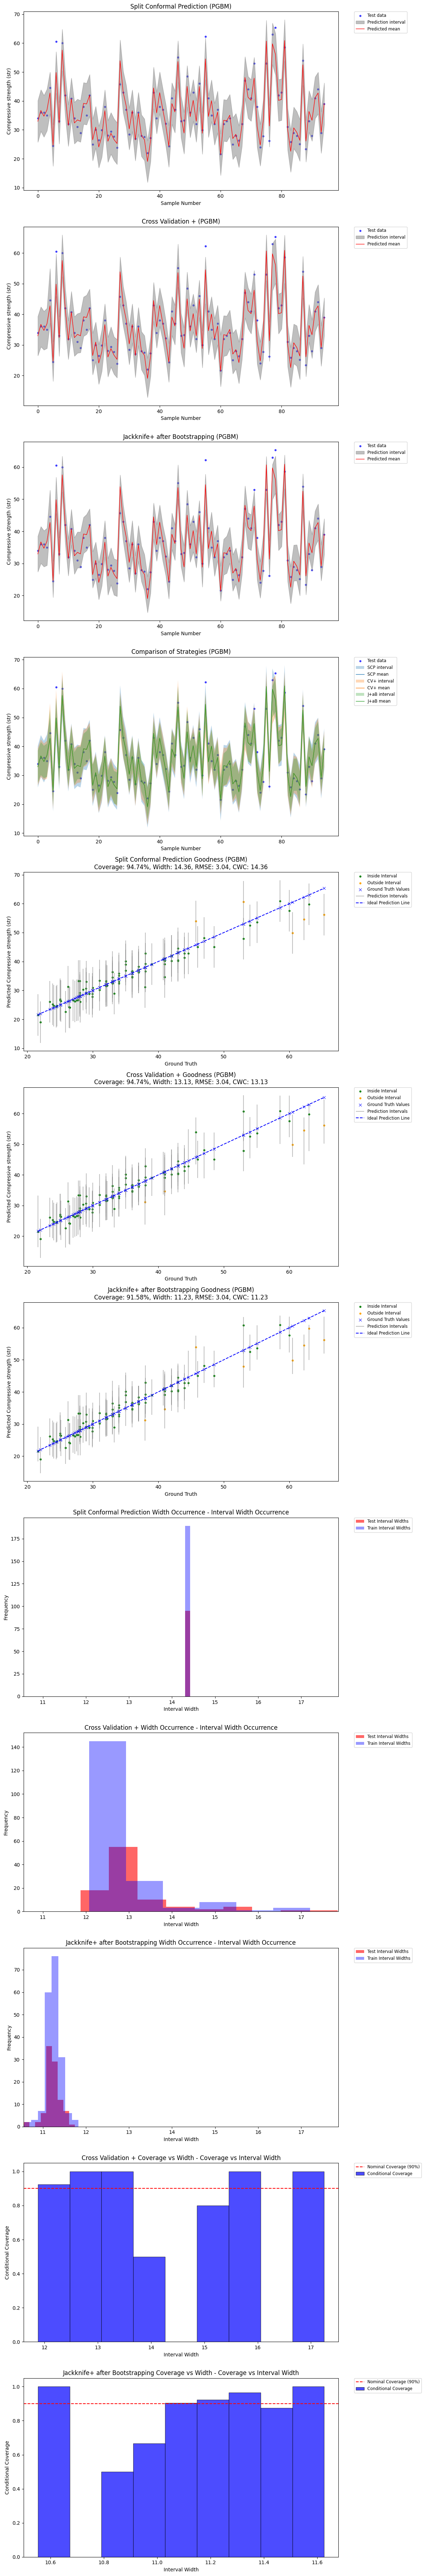

In [48]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax



def conformal_predictions_MAPIE_PGBM(
    model_class,
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name,
    excel_file_path
):
    SEED = 123
    np.random.seed(SEED)
    MISCOVERAGE = ALPHA  # FIX M4: was 0.05
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)

    # Convert y_test to a NumPy array if it has to_numpy
    y_test_np = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test

    # Map method names to descriptive labels
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }

    # Corresponding parameters for each strategy
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Create a base estimator object for each strategy
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    # Fit & predict using MapieRegressor for each strategy
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)


    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred)
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the intervals and predictions for each strategy
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names)*3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(12, 6 * n_figs))
    plot_index = 0

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                            color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red',
                                    label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Comparison subplot (moved after individual strategy plots)
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                        alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name],
                                label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1


    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1


    fig.tight_layout()

    # Save plots to Excel
    # Save plots to Excel
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        sheet_name = 'conformal_predictions_MAPIE'
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        #NEW: Save all predictions/intervals to one worksheet
        all_rows = []
        # Always use y_test_np for consistent array-ness
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = ((y_test_np >= ymin_np) & (y_test_np <= ymax_np)).astype(int)
            residual_np = y_test_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_test_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np,
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet2 = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet2.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet2.cell(row=i+2, column=j, value=float(value) if isinstance(value, np.generic) else value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))



# Example call (assuming best_params, X_train, y_train, X_test, y_test are defined elsewhere)
conformal_predictions_MAPIE_PGBM(
    model_class=PGBMWrapper,
    best_params=best_params,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="PGBM",
    excel_file_path="./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx"
)

In [49]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC_PGBM(
    X_train,
    y_train,
    X_test,
    y_test,
    best_scores_autosampler,
    model_class,
    excel_file_path=None,
    model_params=None,
    alpha=ALPHA  # FIX M4: was 0.1
):
    if model_params is None:
        if model_class.__name__ == 'PGBMWrapper':
            model_params = get_best_model_params(best_scores_autosampler, 'PGBM')
        else:
            model_params = {}

    # Initialize model
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    # Convert to NumPy arrays if needed
    y_train_np = y_train.to_numpy() if isinstance(y_train, pd.Series) else y_train
    model.fit(X_train, y_train_np)

    y_test_np = y_test.to_numpy() if isinstance(y_test, pd.Series) else y_test

    def evaluate_cp(X_test_eval, y_test_eval, model_cp, alpha_val):
        X_test_np = X_test_eval.to_numpy() if isinstance(X_test_eval, pd.DataFrame) else np.array(X_test_eval)
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test_np, alpha=alpha_val)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test_eval, y_pred_lower, y_pred_upper)
        return y_pred, y_pred_lower, y_pred_upper, sharpness, coverage

    # Base predictor setup
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train_np, fit_ratio=0.5)

    y_pred_sc, y_lower_sc, y_upper_sc, sharpness_sc, coverage_sc = evaluate_cp(X_test, y_test_np, splitcp, alpha)

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train_np)
    y_pred, y_lower_cv, y_upper_cv, sharpness_cv, coverage_cv = evaluate_cp(X_test, y_test_np, cvplus, alpha)

    # CQR
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train_np, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_lower_cqr, y_upper_cqr, sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test_np, cqr, alpha)
    y_pred_cqr = 0.5 * (y_lower_cqr + y_upper_cqr)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness_sc:.3f}")
    print(f"SplitCP - Average coverage: {coverage_sc*100:.3f}%")
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cv:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cv*100:.3f}%")
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")


    # Plotting
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    sample_indices = np.arange(len(y_test_np))

    # Plot results for each method
    for idx, (y_pred, y_lower, y_upper, title) in enumerate([
        (y_pred_sc, y_lower_sc, y_upper_sc, 'SplitCP'),
        (y_pred_sc, y_lower_cv, y_upper_cv, 'CVPlus'),
        (y_pred_cqr, y_lower_cqr, y_upper_cqr, 'CQR')
    ]):
        axs[idx].scatter(sample_indices, y_test_np, label='True', color='blue', s=10, alpha=0.7)
        axs[idx].fill_between(sample_indices, y_lower, y_upper, color='gray', alpha=0.5, label='Prediction interval')
        axs[idx].plot(sample_indices, y_pred, color='red', label='Predicted mean', linewidth=1)
        axs[idx].set_title(f'{title}: Prediction Intervals with Conformal Prediction')
        axs[idx].set_xlabel('Sample Number')
        axs[idx].set_ylabel(f'{TARGET_LABEL}')
        axs[idx].legend(fontsize='small')

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_sc).reshape(-1),
        'SplitCP_lower': np.asarray(y_lower_sc).reshape(-1),
        'SplitCP_upper': np.asarray(y_upper_sc).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_sc).reshape(-1),
        'CVPlus_lower': np.asarray(y_lower_cv).reshape(-1),
        'CVPlus_upper': np.asarray(y_upper_cv).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

# Example usage (assuming X_train, y_train, X_test, y_test, best_scores_autosampler exist):
conformal_predictions_PUNCC_PGBM(
    X_train, y_train,
    X_test, y_test,
    best_scores_autosampler=best_scores_autosampler,
    model_class=PGBMWrapper,
    excel_file_path="./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx",
    alpha=0.1
)


Training on CPU
Estimator 0/300, Train metric: 9.3540
Estimator 1/300, Train metric: 8.7014
Estimator 2/300, Train metric: 8.2176
Estimator 3/300, Train metric: 7.7928
Estimator 4/300, Train metric: 7.4588
Estimator 5/300, Train metric: 7.0766
Estimator 6/300, Train metric: 6.7824
Estimator 7/300, Train metric: 6.3936
Estimator 8/300, Train metric: 6.0929
Estimator 9/300, Train metric: 5.8563
Estimator 10/300, Train metric: 5.5902
Estimator 11/300, Train metric: 5.3150
Estimator 12/300, Train metric: 5.1076
Estimator 13/300, Train metric: 4.9502
Estimator 14/300, Train metric: 4.7788
Estimator 15/300, Train metric: 4.6107


Estimator 16/300, Train metric: 4.4217
Estimator 17/300, Train metric: 4.2602
Estimator 18/300, Train metric: 4.0980
Estimator 19/300, Train metric: 3.9577
Estimator 20/300, Train metric: 3.8037
Estimator 21/300, Train metric: 3.6834
Estimator 22/300, Train metric: 3.5716
Estimator 23/300, Train metric: 3.4367
Estimator 24/300, Train metric: 3.3685
Estimator 25/300, Train metric: 3.2836
Estimator 26/300, Train metric: 3.1784
Estimator 27/300, Train metric: 3.1301
Estimator 28/300, Train metric: 3.0346
Estimator 29/300, Train metric: 2.9881
Estimator 30/300, Train metric: 2.9410
Estimator 31/300, Train metric: 2.8818
Estimator 32/300, Train metric: 2.8382


Estimator 33/300, Train metric: 2.7729
Estimator 34/300, Train metric: 2.7350
Estimator 35/300, Train metric: 2.6757
Estimator 36/300, Train metric: 2.6177
Estimator 37/300, Train metric: 2.5424
Estimator 38/300, Train metric: 2.5075
Estimator 39/300, Train metric: 2.4696
Estimator 40/300, Train metric: 2.4056
Estimator 41/300, Train metric: 2.3744
Estimator 42/300, Train metric: 2.3309
Estimator 43/300, Train metric: 2.2890
Estimator 44/300, Train metric: 2.2685
Estimator 45/300, Train metric: 2.2192
Estimator 46/300, Train metric: 2.2087
Estimator 47/300, Train metric: 2.1725
Estimator 48/300, Train metric: 2.1472
Estimator 49/300, Train metric: 2.1308


Estimator 50/300, Train metric: 2.0869
Estimator 51/300, Train metric: 2.0626
Estimator 52/300, Train metric: 2.0371
Estimator 53/300, Train metric: 2.0172
Estimator 54/300, Train metric: 1.9750
Estimator 55/300, Train metric: 1.9376
Estimator 56/300, Train metric: 1.9247
Estimator 57/300, Train metric: 1.8948
Estimator 58/300, Train metric: 1.8667
Estimator 59/300, Train metric: 1.8407
Estimator 60/300, Train metric: 1.8067
Estimator 61/300, Train metric: 1.7990
Estimator 62/300, Train metric: 1.7828
Estimator 63/300, Train metric: 1.7553
Estimator 64/300, Train metric: 1.7234
Estimator 65/300, Train metric: 1.7172
Estimator 66/300, Train metric: 1.6990
Estimator 67/300, Train metric: 1.6698


Estimator 68/300, Train metric: 1.6585
Estimator 69/300, Train metric: 1.6427
Estimator 70/300, Train metric: 1.6199
Estimator 71/300, Train metric: 1.6148
Estimator 72/300, Train metric: 1.5931
Estimator 73/300, Train metric: 1.5767
Estimator 74/300, Train metric: 1.5664
Estimator 75/300, Train metric: 1.5543
Estimator 76/300, Train metric: 1.5420
Estimator 77/300, Train metric: 1.5259
Estimator 78/300, Train metric: 1.5041
Estimator 79/300, Train metric: 1.4966
Estimator 80/300, Train metric: 1.4889
Estimator 81/300, Train metric: 1.4770
Estimator 82/300, Train metric: 1.4581


Estimator 83/300, Train metric: 1.4455
Estimator 84/300, Train metric: 1.4385
Estimator 85/300, Train metric: 1.4257
Estimator 86/300, Train metric: 1.4140
Estimator 87/300, Train metric: 1.4040
Estimator 88/300, Train metric: 1.3936
Estimator 89/300, Train metric: 1.3728
Estimator 90/300, Train metric: 1.3609
Estimator 91/300, Train metric: 1.3531
Estimator 92/300, Train metric: 1.3427
Estimator 93/300, Train metric: 1.3306
Estimator 94/300, Train metric: 1.3222
Estimator 95/300, Train metric: 1.3169
Estimator 96/300, Train metric: 1.3083
Estimator 97/300, Train metric: 1.3043
Estimator 98/300, Train metric: 1.2894
Estimator 99/300, Train metric: 1.2796


... (124 outputs left out)

Estimator 207/300, Train metric: 0.8448
Estimator 208/300, Train metric: 0.8415
Estimator 209/300, Train metric: 0.8411
Estimator 210/300, Train metric: 0.8405
Estimator 211/300, Train metric: 0.8393
Estimator 212/300, Train metric: 0.8387
Estimator 213/300, Train metric: 0.8347
Estimator 214/300, Train metric: 0.8256
Estimator 215/300, Train metric: 0.8225
Estimator 216/300, Train metric: 0.8223
Estimator 217/300, Train metric: 0.8200
Estimator 218/300, Train metric: 0.8139
Estimator 219/300, Train metric: 0.8093
Estimator 220/300, Train metric: 0.8054
Estimator 221/300, Train metric: 0.8023
Estimator 222/300, Train metric: 0.8016
Estimator 223/300, Train metric: 0.7967
Estimator 224/300, Train metric: 0.7953
Estimator 225/300, Train metric: 0.7923
Estimator 226/300, Train metric: 0.7854
Estimator 227/300, Train metric: 0.7814
Estimator 228/300, Train metric: 0.7799
Estimator 229/300, Train metric: 0.7769
Estimator 230/300, Train metric: 0.7765
Estimator 231/300, Train metric: 0.7726


Estimator 237/300, Train metric: 0.7607
Estimator 238/300, Train metric: 0.7583
Estimator 239/300, Train metric: 0.7558
Estimator 240/300, Train metric: 0.7527
Estimator 241/300, Train metric: 0.7506
Estimator 242/300, Train metric: 0.7488
Estimator 243/300, Train metric: 0.7475
Estimator 244/300, Train metric: 0.7446
Estimator 245/300, Train metric: 0.7422
Estimator 246/300, Train metric: 0.7374
Estimator 247/300, Train metric: 0.7390
Estimator 248/300, Train metric: 0.7359
Estimator 249/300, Train metric: 0.7336
Estimator 250/300, Train metric: 0.7345
Estimator 251/300, Train metric: 0.7354
Estimator 252/300, Train metric: 0.7281
Estimator 253/300, Train metric: 0.7290
Estimator 254/300, Train metric: 0.7314
Estimator 255/300, Train metric: 0.7300
Estimator 256/300, Train metric: 0.7244
Estimator 257/300, Train metric: 0.7251
Estimator 258/300, Train metric: 0.7224
Estimator 259/300, Train metric: 0.7191
Estimator 260/300, Train metric: 0.7172
Estimator 261/300, Train metric: 0.7153


Estimator 269/300, Train metric: 0.6932
Estimator 270/300, Train metric: 0.6925
Estimator 271/300, Train metric: 0.6906
Estimator 272/300, Train metric: 0.6839
Estimator 273/300, Train metric: 0.6838
Estimator 274/300, Train metric: 0.6827
Estimator 275/300, Train metric: 0.6809
Estimator 276/300, Train metric: 0.6809
Estimator 277/300, Train metric: 0.6824
Estimator 278/300, Train metric: 0.6820
Estimator 279/300, Train metric: 0.6805
Estimator 280/300, Train metric: 0.6808
Estimator 281/300, Train metric: 0.6792
Estimator 282/300, Train metric: 0.6792
Estimator 283/300, Train metric: 0.6805
Estimator 284/300, Train metric: 0.6770
Estimator 285/300, Train metric: 0.6759
Estimator 286/300, Train metric: 0.6753
Estimator 287/300, Train metric: 0.6742
Estimator 288/300, Train metric: 0.6733
Estimator 289/300, Train metric: 0.6743
Estimator 290/300, Train metric: 0.6719
Estimator 291/300, Train metric: 0.6735
Estimator 292/300, Train metric: 0.6706
Estimator 293/300, Train metric: 0.6713


SplitCP - Average prediction intervals width (sharpness): 12.576
SplitCP - Average coverage: 93.684%
CVPlus - Average prediction intervals width (sharpness): 12.616
CVPlus - Average coverage: 94.737%
CQR - Average prediction intervals width (sharpness): 31.363
CQR - Average coverage: 97.895%


In [50]:
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, PGBMWrapper, best_params,"./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx", "PGBM Prediction Intervals")

Training on CPU
Estimator 0/300, Train metric: 9.3540
Estimator 1/300, Train metric: 8.7014
Estimator 2/300, Train metric: 8.2176
Estimator 3/300, Train metric: 7.7928
Estimator 4/300, Train metric: 7.4588
Estimator 5/300, Train metric: 7.0766
Estimator 6/300, Train metric: 6.7824
Estimator 7/300, Train metric: 6.3936
Estimator 8/300, Train metric: 6.0929
Estimator 9/300, Train metric: 5.8563
Estimator 10/300, Train metric: 5.5902
Estimator 11/300, Train metric: 5.3150
Estimator 12/300, Train metric: 5.1076
Estimator 13/300, Train metric: 4.9502
Estimator 14/300, Train metric: 4.7788
Estimator 15/300, Train metric: 4.6107
Estimator 16/300, Train metric: 4.4217


Estimator 17/300, Train metric: 4.2602
Estimator 18/300, Train metric: 4.0980
Estimator 19/300, Train metric: 3.9577
Estimator 20/300, Train metric: 3.8037
Estimator 21/300, Train metric: 3.6834
Estimator 22/300, Train metric: 3.5716
Estimator 23/300, Train metric: 3.4367
Estimator 24/300, Train metric: 3.3685
Estimator 25/300, Train metric: 3.2836
Estimator 26/300, Train metric: 3.1784
Estimator 27/300, Train metric: 3.1301
Estimator 28/300, Train metric: 3.0346
Estimator 29/300, Train metric: 2.9881
Estimator 30/300, Train metric: 2.9410
Estimator 31/300, Train metric: 2.8818
Estimator 32/300, Train metric: 2.8382
Estimator 33/300, Train metric: 2.7729


Estimator 34/300, Train metric: 2.7350
Estimator 35/300, Train metric: 2.6757
Estimator 36/300, Train metric: 2.6177
Estimator 37/300, Train metric: 2.5424
Estimator 38/300, Train metric: 2.5075
Estimator 39/300, Train metric: 2.4696
Estimator 40/300, Train metric: 2.4056
Estimator 41/300, Train metric: 2.3744
Estimator 42/300, Train metric: 2.3309
Estimator 43/300, Train metric: 2.2890
Estimator 44/300, Train metric: 2.2685
Estimator 45/300, Train metric: 2.2192
Estimator 46/300, Train metric: 2.2087
Estimator 47/300, Train metric: 2.1725
Estimator 48/300, Train metric: 2.1472
Estimator 49/300, Train metric: 2.1308
Estimator 50/300, Train metric: 2.0869


Estimator 51/300, Train metric: 2.0626
Estimator 52/300, Train metric: 2.0371
Estimator 53/300, Train metric: 2.0172
Estimator 54/300, Train metric: 1.9750
Estimator 55/300, Train metric: 1.9376
Estimator 56/300, Train metric: 1.9247
Estimator 57/300, Train metric: 1.8948
Estimator 58/300, Train metric: 1.8667
Estimator 59/300, Train metric: 1.8407
Estimator 60/300, Train metric: 1.8067
Estimator 61/300, Train metric: 1.7990
Estimator 62/300, Train metric: 1.7828
Estimator 63/300, Train metric: 1.7553
Estimator 64/300, Train metric: 1.7234
Estimator 65/300, Train metric: 1.7172
Estimator 66/300, Train metric: 1.6990
Estimator 67/300, Train metric: 1.6698


Estimator 68/300, Train metric: 1.6585
Estimator 69/300, Train metric: 1.6427
Estimator 70/300, Train metric: 1.6199
Estimator 71/300, Train metric: 1.6148
Estimator 72/300, Train metric: 1.5931
Estimator 73/300, Train metric: 1.5767
Estimator 74/300, Train metric: 1.5664
Estimator 75/300, Train metric: 1.5543
Estimator 76/300, Train metric: 1.5420
Estimator 77/300, Train metric: 1.5259
Estimator 78/300, Train metric: 1.5041
Estimator 79/300, Train metric: 1.4966
Estimator 80/300, Train metric: 1.4889
Estimator 81/300, Train metric: 1.4770
Estimator 82/300, Train metric: 1.4581
Estimator 83/300, Train metric: 1.4455
Estimator 84/300, Train metric: 1.4385


Estimator 85/300, Train metric: 1.4257
Estimator 86/300, Train metric: 1.4140
Estimator 87/300, Train metric: 1.4040
Estimator 88/300, Train metric: 1.3936
Estimator 89/300, Train metric: 1.3728
Estimator 90/300, Train metric: 1.3609
Estimator 91/300, Train metric: 1.3531
Estimator 92/300, Train metric: 1.3427
Estimator 93/300, Train metric: 1.3306
Estimator 94/300, Train metric: 1.3222
Estimator 95/300, Train metric: 1.3169
Estimator 96/300, Train metric: 1.3083
Estimator 97/300, Train metric: 1.3043
Estimator 98/300, Train metric: 1.2894
Estimator 99/300, Train metric: 1.2796
Estimator 100/300, Train metric: 1.2633
Estimator 101/300, Train metric: 1.2546
Estimator 102/300, Train metric: 1.2508


... (724 outputs left out)

Estimator 211/300, Train metric: 0.6219
Estimator 212/300, Train metric: 0.6213
Estimator 213/300, Train metric: 0.6208
Estimator 214/300, Train metric: 0.6183
Estimator 215/300, Train metric: 0.6179
Estimator 216/300, Train metric: 0.6166
Estimator 217/300, Train metric: 0.6163
Estimator 218/300, Train metric: 0.6149
Estimator 219/300, Train metric: 0.6136
Estimator 220/300, Train metric: 0.6141
Estimator 221/300, Train metric: 0.6145
Estimator 222/300, Train metric: 0.6138
Estimator 223/300, Train metric: 0.6119
Estimator 224/300, Train metric: 0.6096
Estimator 225/300, Train metric: 0.6096
Estimator 226/300, Train metric: 0.6072
Estimator 227/300, Train metric: 0.6067
Estimator 228/300, Train metric: 0.6062
Estimator 229/300, Train metric: 0.6055
Estimator 230/300, Train metric: 0.6026
Estimator 231/300, Train metric: 0.6030
Estimator 232/300, Train metric: 0.6012
Estimator 233/300, Train metric: 0.6008
Estimator 234/300, Train metric: 0.6002
Estimator 235/300, Train metric: 0.5994


Estimator 237/300, Train metric: 0.5968
Estimator 238/300, Train metric: 0.5941
Estimator 239/300, Train metric: 0.5935
Estimator 240/300, Train metric: 0.5917
Estimator 241/300, Train metric: 0.5913
Estimator 242/300, Train metric: 0.5905
Estimator 243/300, Train metric: 0.5884
Estimator 244/300, Train metric: 0.5863
Estimator 245/300, Train metric: 0.5854
Estimator 246/300, Train metric: 0.5852
Estimator 247/300, Train metric: 0.5853
Estimator 248/300, Train metric: 0.5824
Estimator 249/300, Train metric: 0.5808
Estimator 250/300, Train metric: 0.5801
Estimator 251/300, Train metric: 0.5779
Estimator 252/300, Train metric: 0.5772
Estimator 253/300, Train metric: 0.5760
Estimator 254/300, Train metric: 0.5743
Estimator 255/300, Train metric: 0.5730
Estimator 256/300, Train metric: 0.5720
Estimator 257/300, Train metric: 0.5690
Estimator 258/300, Train metric: 0.5693
Estimator 259/300, Train metric: 0.5690
Estimator 260/300, Train metric: 0.5667
Estimator 261/300, Train metric: 0.5672


Estimator 263/300, Train metric: 0.5647
Estimator 264/300, Train metric: 0.5627
Estimator 265/300, Train metric: 0.5617
Estimator 266/300, Train metric: 0.5615
Estimator 267/300, Train metric: 0.5618
Estimator 268/300, Train metric: 0.5602
Estimator 269/300, Train metric: 0.5593
Estimator 270/300, Train metric: 0.5588
Estimator 271/300, Train metric: 0.5574
Estimator 272/300, Train metric: 0.5558
Estimator 273/300, Train metric: 0.5545
Estimator 274/300, Train metric: 0.5536
Estimator 275/300, Train metric: 0.5524
Estimator 276/300, Train metric: 0.5520
Estimator 277/300, Train metric: 0.5497
Estimator 278/300, Train metric: 0.5476
Estimator 279/300, Train metric: 0.5464
Estimator 280/300, Train metric: 0.5465
Estimator 281/300, Train metric: 0.5467
Estimator 282/300, Train metric: 0.5459
Estimator 283/300, Train metric: 0.5454
Estimator 284/300, Train metric: 0.5445
Estimator 285/300, Train metric: 0.5436
Estimator 286/300, Train metric: 0.5422
Estimator 287/300, Train metric: 0.5417


Estimator 289/300, Train metric: 0.5410
Estimator 290/300, Train metric: 0.5408
Estimator 291/300, Train metric: 0.5404
Estimator 292/300, Train metric: 0.5396
Estimator 293/300, Train metric: 0.5400
Estimator 294/300, Train metric: 0.5395
Estimator 295/300, Train metric: 0.5400
Estimator 296/300, Train metric: 0.5395
Estimator 297/300, Train metric: 0.5389
Estimator 298/300, Train metric: 0.5377
Estimator 299/300, Train metric: 0.5363


# **Conformal Predictions with TabNet**

In [51]:
best_params = get_best_model_params(best_scores_autosampler, 'TabNet')
print(best_params)

{'n_d': 32, 'n_a': 32, 'n_steps': 3, 'gamma': 1.5, 'lambda_sparse': 0.0001, 'optimizer_params': {'lr': 0.02}, 'mask_type': 'entmax', 'n_shared': 1, 'n_independent': 1, 'scheduler_params': {'step_size': 10, 'gamma': 0.9}, 'scheduler_fn': <class 'torch.optim.lr_scheduler.StepLR'>, 'seed': 42, 'verbose': 0}


In [52]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class TabNetRegressorCP(TabNetRegressor):
    def fit(self, X, y, *args, **kwargs):
        y_ = np.array(y)
        if y_.ndim == 1:
            y_ = y_.reshape(-1, 1)
        return super().fit(X, y_, *args, **kwargs)
    def predict(self, X, *args, **kwargs):
        preds = super().predict(X, *args, **kwargs)
        return preds.flatten()
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.mean((y_arr >= int_pred[strat_name][:, 0]) & (y_arr <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.sqrt(mean_squared_error(y_arr, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        y_arr = np.array(y_test)
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_arr[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) &
                                           (y_arr[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan)
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages
class visualize:
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        y_true_np = np.array(y_true).ravel()
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')
        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)],
                 linestyle='--', color='blue', label='Ideal Prediction Line')
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')
        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()
        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]
        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE_tabnet(
    model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path
):
    is_tabnet = ("TabNet" in model_name or "TabNet" in model_class.__name__)

    # Remove 'verbose' if present to avoid TypeError in TabNet
    if isinstance(best_params, dict) and "verbose" in best_params:
        best_params = dict(best_params) # make a copy!
        best_params.pop("verbose", None)

    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    MISCOVERAGE = ALPHA  # FIX M4
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 5},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {}

    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(np.array(X_train), np.array(y_train))
        y_pred_raw, int_pred_raw = mapie.predict(np.array(X_test), alpha=MISCOVERAGE)
        y_pred[strat_name] = y_pred_raw.flatten()
        int_pred[strat_name] = np.array(int_pred_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train_raw, int_pred_train_raw = mapie.predict(np.array(X_train), alpha=MISCOVERAGE)
        y_pred_train[strat_name] = y_pred_train_raw.flatten()
        int_pred_train[strat_name] = np.array(int_pred_train_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # All metric calls now use np.array(y_test)
    coverages = validate.coverage(int_pred, np.array(y_test))
    widths = validate.width(int_pred)
    rmse_vals = validate.rmse(y_pred, np.array(y_test))
    cwc_vals = validate.cwc(int_pred, np.array(y_test), MISCOVERAGE)

    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            rmse = rmse_vals[strat_name]
            interval_width = widths[strat_name]
            coverage = coverages[strat_name]
            cwc = cwc_vals[strat_name]
            ssc = np.mean((np.array(y_test) - y_pred[strat_name])**2 +
                          (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)
            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}\n")

    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS = N_BINS  # FIX D4
    n_figs = len(strategies_names) * 3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))
    plot_index = 0

    # Individual strategy plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)
    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()
            axs[plot_index] = visualize.goodness(
                np.array(y_test), y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})',
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages = validate.cond_coverage(int_pred, np.array(y_test), num_bins=NUM_BINS)
    for _strat in _strategies:
        axs[plot_index] = visualize.coverage_by_width(
            np.array(y_test), int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = f'conformal_predictions_MAPIE_{model_name}'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        # Tabular export
        all_rows = []
        y_true_np = np.array(y_test).ravel()
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np
            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)
        all_pred_sheet_name = 'all_pred_values_' + model_name
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1
        worksheet = workbook.create_sheet(title=all_pred_sheet_name)
        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()


conformal_predictions_MAPIE_tabnet(
    TabNetRegressorCP,        # <------ use the wrapper here!
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    "TabNet",
    "./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx"
)

epoch 0  | loss: 1309.89746|  0:00:00s
epoch 1  | loss: 1196.25562|  0:00:00s
epoch 2  | loss: 1087.57886|  0:00:00s
epoch 3  | loss: 1001.86676|  0:00:00s
epoch 4  | loss: 904.7381|  0:00:00s
epoch 5  | loss: 808.43304|  0:00:00s
epoch 6  | loss: 733.74744|  0:00:00s
epoch 7  | loss: 660.00201|  0:00:00s
epoch 8  | loss: 587.77472|  0:00:00s
epoch 9  | loss: 517.00464|  0:00:00s
epoch 10 | loss: 450.52036|  0:00:00s
epoch 11 | loss: 399.50616|  0:00:00s


epoch 12 | loss: 338.5932|  0:00:00s
epoch 13 | loss: 282.05069|  0:00:00s
epoch 14 | loss: 228.32072|  0:00:00s
epoch 15 | loss: 178.24557|  0:00:00s
epoch 16 | loss: 133.59079|  0:00:00s
epoch 17 | loss: 106.41953|  0:00:00s
epoch 18 | loss: 83.57018|  0:00:00s
epoch 19 | loss: 61.87467|  0:00:00s
epoch 20 | loss: 53.71068|  0:00:00s
epoch 21 | loss: 52.60806|  0:00:00s
epoch 22 | loss: 52.5086 |  0:00:00s
epoch 23 | loss: 55.19965|  0:00:00s


epoch 24 | loss: 53.47669|  0:00:00s
epoch 25 | loss: 62.29683|  0:00:00s
epoch 26 | loss: 50.94538|  0:00:00s
epoch 27 | loss: 52.7476 |  0:00:00s
epoch 28 | loss: 46.76432|  0:00:00s
epoch 29 | loss: 37.22438|  0:00:00s
epoch 30 | loss: 29.57014|  0:00:00s
epoch 31 | loss: 27.9233 |  0:00:00s
epoch 32 | loss: 26.08425|  0:00:00s
epoch 33 | loss: 25.15273|  0:00:00s
epoch 34 | loss: 24.39091|  0:00:00s
epoch 35 | loss: 23.7927 |  0:00:00s


epoch 36 | loss: 21.84422|  0:00:00s
epoch 37 | loss: 18.83226|  0:00:00s
epoch 38 | loss: 17.76406|  0:00:00s
epoch 39 | loss: 17.76846|  0:00:00s
epoch 40 | loss: 17.35579|  0:00:00s
epoch 41 | loss: 17.45917|  0:00:00s
epoch 42 | loss: 16.29972|  0:00:00s
epoch 43 | loss: 16.53415|  0:00:00s
epoch 44 | loss: 19.53166|  0:00:00s
epoch 45 | loss: 16.8646 |  0:00:00s
epoch 46 | loss: 15.94495|  0:00:00s
epoch 47 | loss: 14.57461|  0:00:00s


epoch 48 | loss: 15.36144|  0:00:00s
epoch 49 | loss: 14.67092|  0:00:00s
epoch 50 | loss: 13.82301|  0:00:00s
epoch 51 | loss: 13.57055|  0:00:00s
epoch 52 | loss: 13.11612|  0:00:01s
epoch 53 | loss: 12.82675|  0:00:01s
epoch 54 | loss: 12.35052|  0:00:01s
epoch 55 | loss: 12.06164|  0:00:01s
epoch 56 | loss: 12.19521|  0:00:01s
epoch 57 | loss: 11.90472|  0:00:01s
epoch 58 | loss: 11.48066|  0:00:01s


epoch 59 | loss: 10.9905 |  0:00:01s
epoch 60 | loss: 11.15311|  0:00:01s
epoch 61 | loss: 10.99465|  0:00:01s
epoch 62 | loss: 10.83984|  0:00:01s
epoch 63 | loss: 10.76341|  0:00:01s
epoch 64 | loss: 10.57719|  0:00:01s
epoch 65 | loss: 10.56048|  0:00:01s
epoch 66 | loss: 10.25584|  0:00:01s
epoch 67 | loss: 10.91243|  0:00:01s
epoch 68 | loss: 10.63168|  0:00:01s
epoch 69 | loss: 10.20724|  0:00:01s
epoch 70 | loss: 10.06733|  0:00:01s


... (490 outputs left out)

epoch 75 | loss: 5.77613 |  0:00:01s
epoch 76 | loss: 5.34241 |  0:00:01s
epoch 77 | loss: 5.20355 |  0:00:01s
epoch 78 | loss: 5.07406 |  0:00:01s
epoch 79 | loss: 5.30684 |  0:00:01s
epoch 80 | loss: 4.91219 |  0:00:01s
epoch 81 | loss: 5.05163 |  0:00:01s
epoch 82 | loss: 5.06127 |  0:00:01s
epoch 83 | loss: 4.59883 |  0:00:01s
epoch 84 | loss: 4.60742 |  0:00:01s
epoch 85 | loss: 4.49144 |  0:00:01s
epoch 86 | loss: 3.97415 |  0:00:01s


epoch 87 | loss: 4.49067 |  0:00:01s
epoch 88 | loss: 4.29699 |  0:00:01s
epoch 89 | loss: 4.07491 |  0:00:01s
epoch 90 | loss: 3.71489 |  0:00:01s
epoch 91 | loss: 3.7022  |  0:00:01s
epoch 92 | loss: 4.83615 |  0:00:01s
epoch 93 | loss: 3.9943  |  0:00:01s
epoch 94 | loss: 4.49601 |  0:00:01s
epoch 95 | loss: 4.28556 |  0:00:01s
epoch 96 | loss: 3.70348 |  0:00:01s
epoch 97 | loss: 4.06388 |  0:00:01s
epoch 98 | loss: 3.66477 |  0:00:01s


epoch 99 | loss: 4.21652 |  0:00:01s


Strategy: Split Conformal Prediction
  RMSE: 5.7504
  Interval Width: 20.7548
  Coverage: 90.53%
  CWC: 20.7548
  SSC: 463.8286

Strategy: Cross Validation +
  RMSE: 5.7504
  Interval Width: 27.6672
  Coverage: 97.89%
  CWC: 27.6672
  SSC: 837.0090

Strategy: Jackknife+ after Bootstrapping
  RMSE: 5.7504
  Interval Width: 20.9219
  Coverage: 93.68%
  CWC: 20.9219
  SSC: 473.1764



In [53]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

def conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Get best parameters if not supplied
    if model_params is None:
        model_params = get_best_model_params(best_scores_autosampler, 'TabNet')
        if "verbose" in model_params:
            model_params = dict(model_params)
            model_params.pop("verbose", None)

    model_class = TabNetRegressorCP

    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing TabNet: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_te, y_te, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_te, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(np.array(y_te), y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Base predictor
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    picp_splitcp = np.mean((np.array(y_test).ravel() >= y_pred_lower_splitcp) &
                           (np.array(y_test).ravel() <= y_pred_upper_splitcp))
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")
    print(f"SplitCP - PICP: {picp_splitcp*100:.3f}%")

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness_cvplus, coverage_cvplus = evaluate_cp(X_test, y_test, cvplus, alpha)
    picp_cvplus = np.mean((np.array(y_test).ravel() >= y_pred_lower_cvplus) &
                          (np.array(y_test).ravel() <= y_pred_upper_cvplus))
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cvplus:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cvplus*100:.3f}%")
    print(f"CVPlus - PICP: {picp_cvplus*100:.3f}%\n")

    # CQR
    from sklearn.model_selection import train_test_split
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test, cqr, alpha)
    picp_cqr = np.mean((np.array(y_test).ravel() >= y_pred_lower_cqr) &
                       (np.array(y_test).ravel() <= y_pred_upper_cqr))
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")
    print(f"CQR - PICP: {picp_cqr*100:.3f}%\n")

    # Plot
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    arr_y_test = np.array(y_test).ravel()
    axs[0].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(arr_y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[1].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[2].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(arr_y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export ---
    results_dict = {
        'SplitCP_true': arr_y_test.reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': arr_y_test.reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': arr_y_test.reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC_TabNet')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_TabNet_values')

    plt.close(fig)


conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path="./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    model_params=best_params  # your best params for TabNet
)

SplitCP - Average prediction intervals width (sharpness): 24.703
SplitCP - Average coverage: 88.421%
SplitCP - PICP: 88.421%


CVPlus - Average prediction intervals width (sharpness): 34.459
CVPlus - Average coverage: 100.000%
CVPlus - PICP: 100.000%



CQR - Average prediction intervals width (sharpness): 38.950
CQR - Average coverage: 96.842%
CQR - PICP: 96.842%



In [54]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params,
    excel_file_path=None,
    suptitle: str = "TabNet Prediction Intervals"
) -> None:
    # Use wrapper for TabNet
    model_cls = TabNetRegressorCP

    # Train model with MAPIE
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [np.array(y_train).min(), np.array(y_train).max()],
            [np.array(y_train).min(), np.array(y_train).max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        np.array(y_train).ravel(),
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        np.array(y_test).ravel(),
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        # Use a fresh model each time (sklearn style)
        mapie = MapieRegressor(model_cls(**model_params), **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_2')

    plt.close(fig)

# Helper method for Excel plotting export
def save_plot_to_excel(fig, excel_file_path, sheet_name):
    import io
    from openpyxl import load_workbook
    from openpyxl.drawing.image import Image
    from PIL import Image as PILImage
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PILImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)
        worksheet.add_image(img, 'A1')
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))


prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params=best_params,
    excel_file_path="./drive/MyDrive/Regression/concrete_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    suptitle="TabNet Prediction Intervals"
)